In [134]:
import pandas as pd

In [135]:
df = pd.read_csv('/Users/vladkornilov/Desktop/вшэ/Python_Module_1/hw_3_python/Electronic_sales_Sep2023-Sep2024.csv')
df.head(3)

,Customer ID,Age,Gender,Loyalty Member,Product Type,SKU,Rating,Order Status,Payment Method,Total Price,Unit Price,Quantity,Purchase Date,Shipping Type,Add-ons Purchased,Add-on Total
0,1000,53,Male,No,Smartphone,SKU1004,2,Cancelled,Credit Card,5538.33,791.19,7,2024-03-20,Standard,"Accessory,Accessory,Accessory",40.21
1,1000,53,Male,No,Tablet,SKU1002,3,Completed,Paypal,741.09,247.03,3,2024-04-20,Overnight,Impulse Item,26.09
2,1002,41,Male,No,Laptop,SKU1005,3,Completed,Credit Card,1855.84,463.96,4,2023-10-17,Express,NaN,0.00


In [136]:
df1 = df[['Customer ID', 'Order Status', 'Shipping Type','Product Type', 'Total Price', 'Purchase Date', 'Add-on Total']]

In [137]:
df1.head()

,Customer ID,Order Status,Shipping Type,Product Type,Total Price,Purchase Date,Add-on Total
0,1000,Cancelled,Standard,Smartphone,5538.33,2024-03-20,40.21
1,1000,Completed,Overnight,Tablet,741.09,2024-04-20,26.09
2,1002,Completed,Express,Laptop,1855.84,2023-10-17,0.00
3,1002,Completed,Overnight,Smartphone,3164.76,2024-08-09,60.16
4,1003,Completed,Express,Smartphone,41.50,2024-05-21,35.56


In [138]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer ID    20000 non-null  int64  
 1   Order Status   20000 non-null  object 
 2   Shipping Type  20000 non-null  object 
 3   Product Type   20000 non-null  object 
 4   Total Price    20000 non-null  float64
 5   Purchase Date  20000 non-null  object 
 6   Add-on Total   20000 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 1.1+ MB


In [139]:
df1.isna().sum()

Customer ID      0
Order Status     0
Shipping Type    0
Product Type     0
Total Price      0
Purchase Date    0
Add-on Total     0
dtype: int64

In [140]:
df["Order Status"].value_counts()

Order Status
Completed    13432
Cancelled     6568
Name: count, dtype: int64

In [141]:
df1['Purchase Date'].dtype

dtype('O')

In [142]:
df1['Purchase Date'] = pd.to_datetime(df1['Purchase Date'])

/var/folders/jl/99ht1qgj7q92v0q6fg7hs5hc0000gn/T/ipykernel_4728/3678054771.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Purchase Date'] = pd.to_datetime(df1['Purchase Date'])


In [143]:
df1['Purchase Date'].dtype

dtype('<M8[ns]')

In [144]:
df1[df1['Total Price'] <= 0]

,Customer ID,Order Status,Shipping Type,Product Type,Total Price,Purchase Date,Add-on Total


In [145]:
df1[df1['Add-on Total'] < 0]

,Customer ID,Order Status,Shipping Type,Product Type,Total Price,Purchase Date,Add-on Total


### Очистка данных
Пропуски в датасете отсутствуют.  
Отрицательных и нулевых значений в `Total Price` нет.  
Отрицательных значений в `Add-on Total` нет.  
Столбец `Purchase Date` приведён к типу даты.  

In [146]:
clean_df = df1[df1["Order Status"] == "Completed"]

In [147]:
clean_df

,Customer ID,Order Status,Shipping Type,Product Type,Total Price,Purchase Date,Add-on Total
1,1000,Completed,Overnight,Tablet,741.09,2024-04-20,26.09
2,1002,Completed,Express,Laptop,1855.84,2023-10-17,0.00
3,1002,Completed,Overnight,Smartphone,3164.76,2024-08-09,60.16
4,1003,Completed,Express,Smartphone,41.50,2024-05-21,35.56
5,1004,Completed,Standard,Smartphone,83.00,2024-05-26,65.78
...,...,...,...,...,...,...,...
19991,19995,Completed,Same Day,Laptop,5394.56,2024-08-09,0.00
19994,19996,Completed,Same Day,Smartphone,3419.04,2024-04-20,0.00
19995,19996,Completed,Expedited,Smartphone,6838.08,2024-06-15,0.00
19997,19996,Completed,Standard,Headphones,1805.90,2024-08-26,198.98


In [148]:
revenue_by_shipping = clean_df.groupby('Shipping Type')['Total Price'].sum()

In [149]:
revenue_by_shipping = revenue_by_shipping.reset_index()

In [150]:
revenue_by_shipping

,Shipping Type,Total Price
0,Expedited,8430385.58
1,Express,5632093.35
2,Overnight,5887722.52
3,Same Day,8292376.50
4,Standard,14387037.62


In [185]:
revenue_by_shipping = revenue_by_shipping.rename(columns = {'Total Price': 'revenue_by_shipping'})

In [152]:
revenue_by_product_type = clean_df.groupby('Product Type')['Total Price'].sum()

In [153]:
revenue_by_product_type = revenue_by_product_type.reset_index()

In [192]:
revenue_by_product_type = revenue_by_product_type.rename(columns = {'Total Price': 'revenue_by_product_type'})

In [155]:
clean_df['month'] = clean_df['Purchase Date'].dt.to_period('M')

/var/folders/jl/99ht1qgj7q92v0q6fg7hs5hc0000gn/T/ipykernel_4728/917634046.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_df['month'] = clean_df['Purchase Date'].dt.to_period('M')


In [156]:
clean_df

,Customer ID,Order Status,Shipping Type,Product Type,Total Price,Purchase Date,Add-on Total,month
1,1000,Completed,Overnight,Tablet,741.09,2024-04-20,26.09,2024-04
2,1002,Completed,Express,Laptop,1855.84,2023-10-17,0.00,2023-10
3,1002,Completed,Overnight,Smartphone,3164.76,2024-08-09,60.16,2024-08
4,1003,Completed,Express,Smartphone,41.50,2024-05-21,35.56,2024-05
5,1004,Completed,Standard,Smartphone,83.00,2024-05-26,65.78,2024-05
...,...,...,...,...,...,...,...,...
19991,19995,Completed,Same Day,Laptop,5394.56,2024-08-09,0.00,2024-08
19994,19996,Completed,Same Day,Smartphone,3419.04,2024-04-20,0.00,2024-04
19995,19996,Completed,Expedited,Smartphone,6838.08,2024-06-15,0.00,2024-06
19997,19996,Completed,Standard,Headphones,1805.90,2024-08-26,198.98,2024-08


In [157]:
addons_by_month = clean_df.groupby('month')['Add-on Total'].sum()

In [158]:
addons_by_month = addons_by_month.reset_index()

In [159]:
addons_by_month = addons_by_month.rename(columns = {'Add-on Total': 'addons_revenue_month'})

In [160]:
clean_df['quarter'] = clean_df['Purchase Date'].dt.to_period('Q')

/var/folders/jl/99ht1qgj7q92v0q6fg7hs5hc0000gn/T/ipykernel_4728/3369318368.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_df['quarter'] = clean_df['Purchase Date'].dt.to_period('Q')


In [161]:
clean_df

,Customer ID,Order Status,Shipping Type,Product Type,Total Price,Purchase Date,Add-on Total,month,quarter
1,1000,Completed,Overnight,Tablet,741.09,2024-04-20,26.09,2024-04,2024Q2
2,1002,Completed,Express,Laptop,1855.84,2023-10-17,0.00,2023-10,2023Q4
3,1002,Completed,Overnight,Smartphone,3164.76,2024-08-09,60.16,2024-08,2024Q3
4,1003,Completed,Express,Smartphone,41.50,2024-05-21,35.56,2024-05,2024Q2
5,1004,Completed,Standard,Smartphone,83.00,2024-05-26,65.78,2024-05,2024Q2
...,...,...,...,...,...,...,...,...,...
19991,19995,Completed,Same Day,Laptop,5394.56,2024-08-09,0.00,2024-08,2024Q3
19994,19996,Completed,Same Day,Smartphone,3419.04,2024-04-20,0.00,2024-04,2024Q2
19995,19996,Completed,Expedited,Smartphone,6838.08,2024-06-15,0.00,2024-06,2024Q2
19997,19996,Completed,Standard,Headphones,1805.90,2024-08-26,198.98,2024-08,2024Q3


In [162]:
addons_by_quarter = clean_df.groupby('quarter')['Add-on Total'].sum()

In [163]:
addons_by_quarter=addons_by_quarter.reset_index()

In [164]:
addons_by_quarter = addons_by_quarter.rename(columns = {'Add-on Total': 'addons_revenue_quarter'})

In [165]:
addons_by_quarter

,quarter,addons_revenue_quarter
0,2023Q3,5337.61
1,2023Q4,73356.77
2,2024Q1,258222.60
3,2024Q2,256316.84
4,2024Q3,242361.42


In [166]:
first_purchases = clean_df.groupby('Customer ID')['month'].min()

In [167]:
first_purchases = first_purchases.reset_index()

In [168]:
first_purchases = first_purchases.rename(columns = {'month': 'cohort'})

In [169]:
clean_df = clean_df.merge(first_purchases, on='Customer ID')

In [170]:
clean_df["cohort_month"] = (
    clean_df["month"].astype(int) - clean_df["cohort"].astype(int)
)

In [171]:
cohort_df = clean_df[clean_df['cohort_month'].isin([0,1,2,3])]

In [172]:
cohort_revenue = cohort_df.groupby(['cohort', 'cohort_month'])['Total Price'].sum()

In [173]:
cohort_revenue = cohort_revenue.unstack()

In [174]:
cohort_revenue

cohort_month,0,1,2,3
cohort,,,,
2023-09,283635.75,33456.62,26608.97,33037.33
2023-10,1521869.24,56062.66,104107.36,104115.98
2023-11,1307444.87,50714.25,118382.28,48411.54
2023-12,1122163.93,69367.01,50377.99,64964.23
2024-01,4212120.86,219854.68,355993.76,361010.49
2024-02,3479301.96,233334.29,253779.99,271156.10
2024-03,3424078.59,303436.44,244533.72,242932.43
2024-04,3115300.96,250017.51,265710.65,241513.21
2024-05,3066715.91,180702.17,238287.75,181550.20


In [175]:
cohort_customers = cohort_df.groupby(['cohort', 'cohort_month'])['Customer ID'].nunique()

In [176]:
cohort_customers = cohort_customers.unstack()

In [177]:
cohort_customers

cohort_month,0,1,2,3
cohort,,,,
2023-09,121.0,11.0,12.0,12.0
2023-10,581.0,27.0,35.0,36.0
2023-11,482.0,21.0,39.0,24.0
2023-12,442.0,27.0,16.0,23.0
2024-01,1236.0,72.0,88.0,88.0
2024-02,1029.0,65.0,71.0,75.0
2024-03,1028.0,77.0,71.0,72.0
2024-04,907.0,76.0,73.0,63.0
2024-05,906.0,53.0,66.0,50.0


In [179]:
import matplotlib.pyplot as plt

In [184]:
revenue_by_shipping.head()

,Shipping Type,Total Price
0,Expedited,8430385.58
1,Express,5632093.35
2,Overnight,5887722.52
3,Same Day,8292376.50
4,Standard,14387037.62


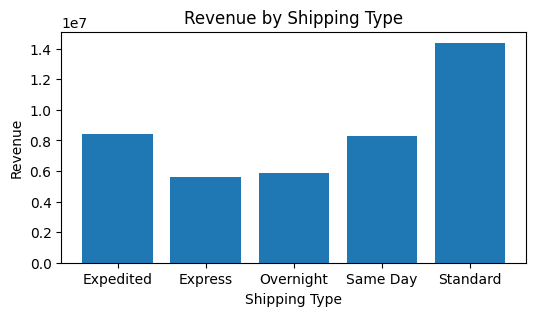

In [188]:
plt.figure(figsize=(6, 3))

plt.bar(
    revenue_by_shipping["Shipping Type"],
    revenue_by_shipping["revenue_by_shipping"]
)

plt.xlabel("Shipping Type")
plt.ylabel("Revenue")
plt.title("Revenue by Shipping Type")

plt.show()

In [193]:
revenue_by_product_type.head()

,Product Type,revenue_by_product_type
0,Headphones,2734651.00
1,Laptop,8365905.25
2,Smartphone,14407835.84
3,Smartwatch,9398591.23
4,Tablet,7722632.25


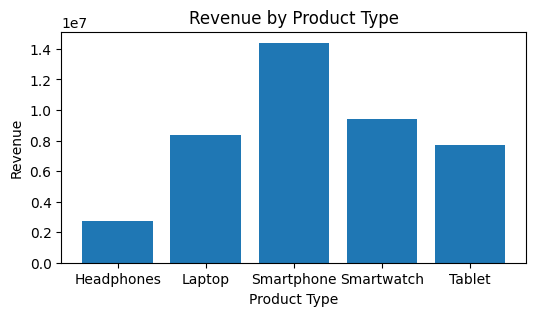

In [194]:
plt.figure(figsize=(6, 3))

plt.bar(
    revenue_by_product_type['Product Type'],
    revenue_by_product_type['revenue_by_product_type']
)

plt.xlabel('Product Type')
plt.ylabel('Revenue')
plt.title('Revenue by Product Type')

plt.show()

In [197]:
addons_by_month['month'] = addons_by_month['month'].astype(str)

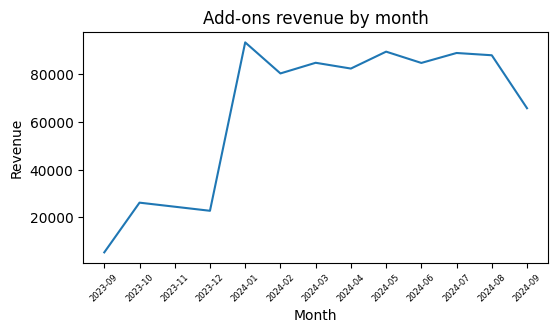

In [201]:
plt.figure(figsize=(6, 3))

plt.plot(
    addons_by_month['month'],
    addons_by_month['addons_revenue_month']
)

plt.xlabel('Month')
plt.xticks(fontsize=6, rotation=45)
plt.ylabel('Revenue')
plt.title('Add-ons revenue by month')

plt.show()

In [202]:
cohort_revenue.head()

cohort_month,0,1,2,3
cohort,,,,
2023-09,283635.75,33456.62,26608.97,33037.33
2023-10,1521869.24,56062.66,104107.36,104115.98
2023-11,1307444.87,50714.25,118382.28,48411.54
2023-12,1122163.93,69367.01,50377.99,64964.23
2024-01,4212120.86,219854.68,355993.76,361010.49


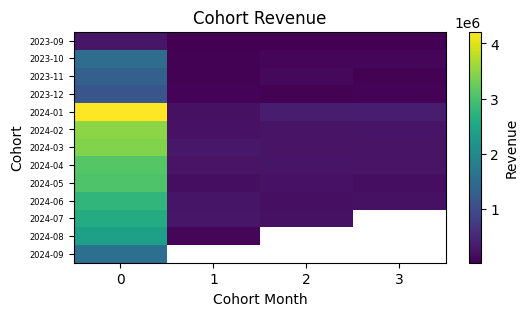

In [208]:
plt.figure(figsize=(6, 3))

plt.imshow(cohort_revenue, aspect='auto')

plt.colorbar(label="Revenue")

plt.xlabel("Cohort Month")
plt.ylabel("Cohort")
plt.title("Cohort Revenue")

plt.xticks(range(len(cohort_revenue.columns)), cohort_revenue.columns)
plt.yticks(range(len(cohort_revenue.index)), cohort_revenue.index.astype(str), fontsize=6)


plt.show()

In [218]:
metrics = {
    "revenue_by_shipping": revenue_by_shipping,
    "revenue_by_product_type": revenue_by_product_type,
    "addons_by_month": addons_by_month,
    "addons_by_quarter": addons_by_quarter,
    "cohort_revenue": cohort_revenue,
    "cohort_customers": cohort_customers
}

In [222]:
metrics["cohort_customers"]

cohort_month,0,1,2,3
cohort,,,,
2023-09,121.0,11.0,12.0,12.0
2023-10,581.0,27.0,35.0,36.0
2023-11,482.0,21.0,39.0,24.0
2023-12,442.0,27.0,16.0,23.0
2024-01,1236.0,72.0,88.0,88.0
2024-02,1029.0,65.0,71.0,75.0
2024-03,1028.0,77.0,71.0,72.0
2024-04,907.0,76.0,73.0,63.0
2024-05,906.0,53.0,66.0,50.0


## Дополнительное задание

In [224]:
def clean(df):
    clean_df = df.copy()
    clean_df['Purchase Date'] = pd.to_datetime(clean_df['Purchase Date'])
    clean_df = clean_df[clean_df['Order Status'] == 'Completed']
    clean_df = clean_df[clean_df['Total Price'] > 0]
    clean_df = clean_df[clean_df['Add-on Total'] >= 0]
    return clean_df

In [225]:
cleaned_test_df = clean(df1)

In [240]:
def build_metrics(df):
    revenue_by_shipping = df.groupby('Shipping Type')['Total Price'].sum().reset_index()
    revenue_by_shipping = revenue_by_shipping.rename(columns = {'Total Price': 'revenue_by_shipping'})

    revenue_by_product_type = df.groupby('Product Type')['Total Price'].sum().reset_index()
    revenue_by_product_type = revenue_by_product_type.rename(columns = {'Total Price': 'revenue_by_product_type'})

    df['month'] = df['Purchase Date'].dt.to_period('M')
    addons_by_month = df.groupby('month')['Add-on Total'].sum().reset_index()
    addons_by_month = addons_by_month.rename(columns = {'Add-on Total': 'addons_revenue_month'})

    df['quarter'] = df['Purchase Date'].dt.to_period('Q')
    addons_by_quarter = df.groupby('quarter')['Add-on Total'].sum().reset_index()
    addons_by_quarter = addons_by_quarter.rename(columns = {'Add-on Total': 'addons_revenue_quarter'})

    first_purchases = df.groupby('Customer ID')['month'].min().reset_index()
    first_purchases = first_purchases.rename(columns = {'month': 'cohort'})

    df = df.merge(first_purchases, on = 'Customer ID')

    df['cohort_month'] = df['month'].astype(int) - df['cohort'].astype(int)

    cohort_df = df[df['cohort_month'].isin([0, 1, 2, 3])]
    
    cohort_revenue = cohort_df.groupby(['cohort', 'cohort_month'])['Total Price'].sum().unstack()

    cohort_customers = cohort_df.groupby(['cohort', 'cohort_month'])['Customer ID'].nunique().unstack()

    metrics = {
        "revenue_by_shipping": revenue_by_shipping,
        "revenue_by_product": revenue_by_product_type,
        "addons_by_month": addons_by_month,
        "addons_by_quarter": addons_by_quarter,
        "cohort_revenue": cohort_revenue,
        "cohort_customers": cohort_customers
    }

    return metrics




In [241]:
metrics_test_df = build_metrics(cleaned_test_df)

In [248]:
metrics_test_df['cohort_customers']

cohort_month,0,1,2,3
cohort,,,,
2023-09,121.0,11.0,12.0,12.0
2023-10,581.0,27.0,35.0,36.0
2023-11,482.0,21.0,39.0,24.0
2023-12,442.0,27.0,16.0,23.0
2024-01,1236.0,72.0,88.0,88.0
2024-02,1029.0,65.0,71.0,75.0
2024-03,1028.0,77.0,71.0,72.0
2024-04,907.0,76.0,73.0,63.0
2024-05,906.0,53.0,66.0,50.0
